# 01 · Geomagnetic storms: how often, when, and what comes before them

When a burst of solar wind hits Earth's magnetic field hard enough, it causes a geomagnetic storm: it drags satellites down (SpaceX lost about 40 new Starlink satellites to one in February 2022), disrupts GPS and radio, and in extreme cases threatens power grids. The standard measure is the **Kp index**, 0 to 9 every three hours. NOAA calls Kp 5 or more a storm (G1, minor) and Kp 9 extreme (G5).

This notebook looks at the data before any forecasting: how rare storms are, how they follow the Sun's 11-year cycle, what the solar wind does just before one, and a 27-day pattern that one of the baselines will use.

**Data:** the definitive Kp index from GFZ Potsdam, and NASA's OMNI hourly solar wind measured upstream of Earth, 1995 to 2026.

    python scripts/download_data.py

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..") / "src"))
from storms import STORM_KP, daily_max_kp, g_threshold, load_kp, load_omni

kp = load_kp().loc["1995":]
omni = load_omni()
daily = daily_max_kp(kp)
print(f"Kp: {len(kp):,} three-hour values, {kp.index.min():%Y-%m-%d} to {kp.index.max():%Y-%m-%d} "
      f"({kp['definitive'].mean():.1%} definitive, the rest preliminary)")
print(f"Solar wind: {len(omni):,} hours; speed missing in {omni['speed'].isna().mean():.1%}, Bz in {omni['bz'].isna().mean():.1%}")

Kp: 92,744 three-hour values, 1995-01-01 to 2026-09-27 (99.8% definitive, the rest preliminary)
Solar wind: 280,512 hours; speed missing in 1.5%, Bz in 1.4%


## How rare are storms?

Storms are rare, and the biggest ones very rare. Counted by three-hour period and by day (a storm day has at least one period at Kp 5 or more):

In [2]:
levels = {"G1 minor (Kp 5)": 1, "G2 moderate (Kp 6)": 2, "G3 strong (Kp 7)": 3, "G4 severe (Kp 8)": 4, "G5 extreme (Kp 9)": 5}
rows = []
for name, g in levels.items():
    rows.append({"level reached": name,
                 "share of 3-hour periods": (kp["kp"] >= g_threshold(g)).mean(),
                 "share of days": (daily >= g_threshold(g)).mean(),
                 "days": int((daily >= g_threshold(g)).sum())})
table = pd.DataFrame(rows).set_index("level reached")
table.style.format({"share of 3-hour periods": "{:.2%}", "share of days": "{:.2%}", "days": "{:,}"})

,share of 3-hour periods,share of days,days
level reached,,,
G1 minor (Kp 5),4.09%,14.05%,"1,629"
G2 moderate (Kp 6),1.30%,4.99%,579
G3 strong (Kp 7),0.44%,1.71%,198
G4 severe (Kp 8),0.15%,0.60%,70
G5 extreme (Kp 9),0.03%,0.16%,18


Kp comes in thirds (5-, 5o, 5+), and NOAA's G1 threshold is Kp 5-, so each level above counts from its minus third. About one day in eight has a storm, but only a handful of days in thirty years reach G5.

## Storms follow the solar cycle

The Sun's activity rises and falls over about 11 years, measured by the number of sunspots. Storm days per year follow it:

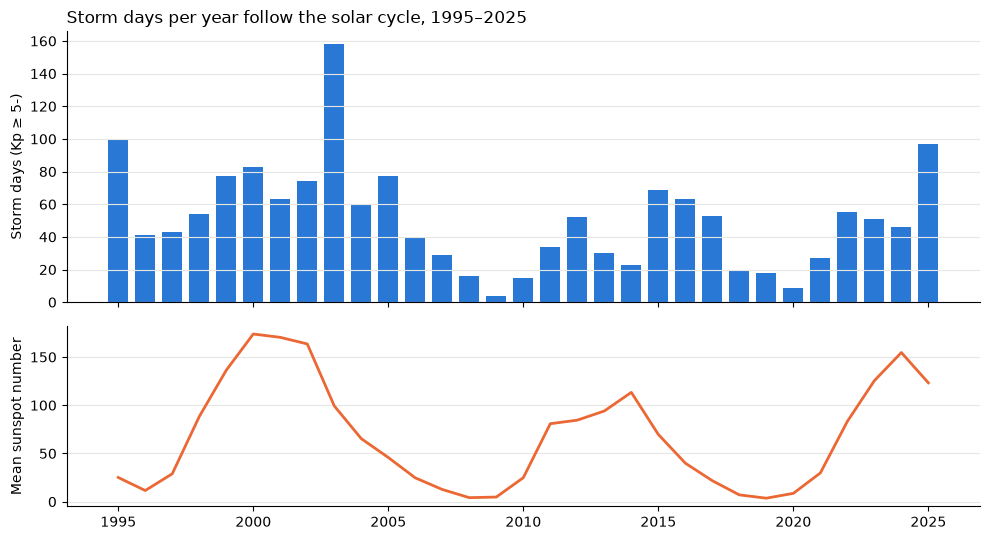

time        1995  1996  1997  1998  1999  2000  2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025
storm_days   100    41    43    54    77    83    63    74   158    60    77    40    29    16     4    15    34    52    30    23    69    63    53    20    18     9    27    55    51    46    97
sunspots      25    11    28    88   136   173   170   163    99    65    45    24    12     4     4    24    80    84    94   113    69    39    21     7     3     8    29    83   125   154   123


In [3]:
years = pd.DataFrame({
    "storm_days": (daily >= STORM_KP).groupby(daily.index.year).sum(),
    "sunspots": omni["sunspots"].groupby(omni.index.year).mean(),
}).loc[1995:2025]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, height_ratios=[3, 2])
top.bar(years.index, years["storm_days"], color="#2a78d6", width=0.75)
top.set_ylabel("Storm days (Kp ≥ 5-)")
top.set_title("Storm days per year follow the solar cycle, 1995–2025", loc="left")
bottom.plot(years.index, years["sunspots"], color="#eb6834", linewidth=2)
bottom.set_ylabel("Mean sunspot number")
for ax in (top, bottom):
    ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
print(years.astype(int).T.to_string())

Two cycles are visible: peaks around 2000–2003 and 2014–2015, and the current cycle 25 climbing since 2020. Storm days lag the sunspot peak slightly: the declining phase of a cycle brings long-lived fast solar wind streams, which cause many moderate storms.

This matters for testing. A model trained mostly on quiet years and tested on active ones (or the reverse) sees a very different share of storms, so results have to be read against the base rate of each period.

## What the solar wind does before a storm

The solar wind is measured about 1.5 million km upstream of Earth, roughly 30 to 60 minutes of travel time before it arrives. The two things that matter most are its **speed** and the **north-south component of its magnetic field, Bz**: when Bz turns strongly southward, it links up with Earth's field and energy pours in. The May 2024 storm, the strongest in two decades, shows it:

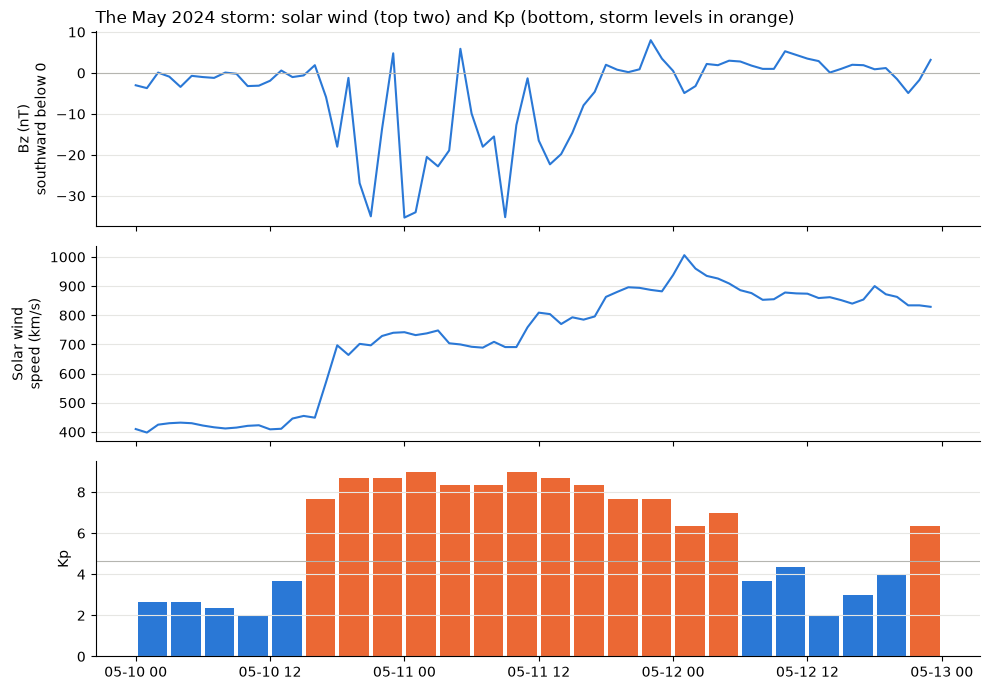

Kp peaked at 9.00; Bz reached -35 nT; speed peaked at 1006 km/s


In [4]:
window = slice("2024-05-10", "2024-05-12")
wind = omni.loc[window]
k = kp.loc[window, "kp"]

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
axes[0].plot(wind.index, wind["bz"], color="#2a78d6", linewidth=1.5)
axes[0].axhline(0, color="#b5b5b0", linewidth=0.8)
axes[0].set_ylabel("Bz (nT)\nsouthward below 0")
axes[1].plot(wind.index, wind["speed"], color="#2a78d6", linewidth=1.5)
axes[1].set_ylabel("Solar wind\nspeed (km/s)")
axes[2].bar(k.index + pd.Timedelta(hours=1.5), k, width=0.11, color=np.where(k >= STORM_KP, "#eb6834", "#2a78d6"))
axes[2].axhline(STORM_KP, color="#b5b5b0", linewidth=0.8)
axes[2].set_ylabel("Kp")
axes[2].set_ylim(0, 9.5)
axes[0].set_title("The May 2024 storm: solar wind (top two) and Kp (bottom, storm levels in orange)", loc="left")
for ax in axes:
    ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
print(f"Kp peaked at {k.max():.2f}; Bz reached {wind['bz'].min():.0f} nT; speed peaked at {wind['speed'].max():.0f} km/s")

Kp jumps within hours of the solar wind turning fast and strongly southward, and stays high for as long as Bz stays south. That's the case for the models: recent solar wind should say a lot about the next few hours. It also shows their limit: with 30 to 60 minutes of warning from the upstream spacecraft, the solar wind itself can't see a storm coming a day ahead. For that, a model has to rely on patterns like the next one.

## The 27-day echo

The Sun rotates about once every 27 days as seen from Earth. Long-lived features on it, like the coronal holes that send out fast solar wind streams, face Earth again a rotation later and can cause storms again. It shows up as a bump in how strongly each day's activity is correlated with activity a given number of days earlier:

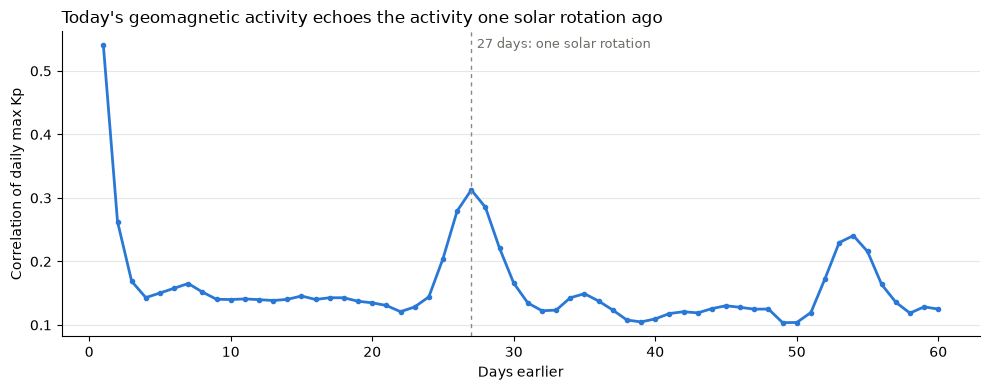

correlation 1 day apart 0.54, 14 days 0.14, 27 days 0.31


In [5]:
lags = np.arange(1, 61)
activity = daily.loc["1995":"2025"]
correlation = [activity.corr(activity.shift(lag)) for lag in lags]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lags, correlation, color="#2a78d6", linewidth=2, marker="o", markersize=3)
ax.axvline(27, color="#8a8a85", linewidth=1, linestyle=(0, (3, 3)))
ax.annotate("27 days: one solar rotation", (27, 1), xycoords=("data", "axes fraction"), xytext=(4, -4),
            textcoords="offset points", va="top", fontsize=9, color="#6b6b66")
ax.set_xlabel("Days earlier")
ax.set_ylabel("Correlation of daily max Kp")
ax.set_title("Today's geomagnetic activity echoes the activity one solar rotation ago", loc="left")
ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
print(f"correlation 1 day apart {correlation[0]:.2f}, 14 days {correlation[13]:.2f}, 27 days {correlation[26]:.2f}")

## What this means for forecasting

- Storms happen on about one day in eight, so a forecast of "no storm" is right most of the time and useless. Forecasts should be judged as probabilities, with the base rate in mind.
- For the next few hours, the solar wind carries most of the information, since it arrives 30 to 60 minutes after it's measured and storms build as it keeps blowing.
- For tomorrow and beyond, the useful signals are slower: how active today was, the 27-day echo, and where we are in the solar cycle.

The next notebook sets the bars a model has to clear: persistence ("tomorrow like today"), the 27-day echo, climatology, and NOAA's own published storm probabilities.